In [324]:
#############################################
# Exploratory Data Analysis
# Author: Ahmed SALLAM
##############################################

# - Temporal variation: How did measles incidence change between 2014 and 2023?
# -  Geographic heterogeneity: Which regions experienced the highest and lowest incidence?
# - Spatiotemporal patterns: Did the same regions consistently experience elevated incidence, or were regional differences driven by individual outbreak years?
# - Outbreak concentration: Were most cases concentrated in particular years and regions?

In [325]:
######################################
# 1. REAGION-BY-YEAR INCIDENCE HEATMAP
######################################

In [326]:
import pandas as pd
from pathlib import Path

# Locate the data folder
data_dir = Path("../data") if Path("../data").exists() else Path("data")

# Load the regional dataset
regional = pd.read_csv(data_dir / "measles_region_year.csv")
annual = pd.read_csv(data_dir / "measles_national_annual.csv")

# Confirm successful loading
print("Dataset loaded successfully!")
print("Shape:", regional.shape)
display(regional.head())

Dataset loaded successfully!
Shape: (200, 7)


,health_region,year,reported_cases,population,annual_incidence_per_100k,region_total_cases_2014_2023,region_aair_per_100k_per_year
0,Riyadh,2014,15,7717467,0.194364,1600,1.918064
1,Riyadh,2015,11,7910864,0.139049,1600,1.918064
2,Riyadh,2016,5,8002100,0.062484,1600,1.918064
3,Riyadh,2017,45,8216284,0.547693,1600,1.918064
4,Riyadh,2018,272,8446866,3.220129,1600,1.918064


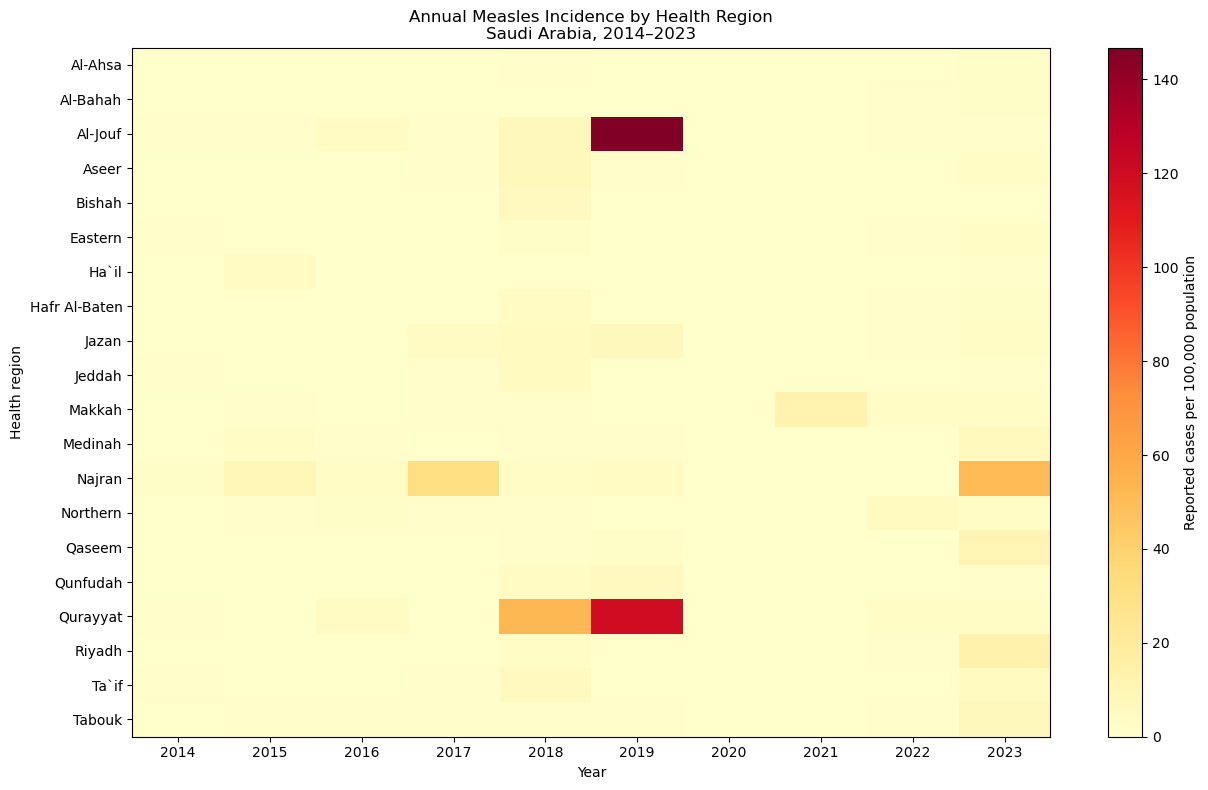

In [327]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

incidence_matrix = regional.pivot(
    index="health_region",
    columns="year",
    values="annual_incidence_per_100k"
)

# sort regions by their 10-year AAIR
region_order = (
    regional.groupby("health_region")[
        "region_aair_per_100k_per_year"
]
.first()
.sort_values(ascending=False)
.index
)

#Plot heatmap
fig, ax = plt.subplots(figsize=(13, 8))

im = ax.imshow(
    incidence_matrix.values,
    aspect="auto",
    cmap="YlOrRd",
    interpolation="nearest"
)

ax.set_xticks(np.arange(len(incidence_matrix.columns)))
ax.set_xticklabels(incidence_matrix.columns)

ax.set_yticks(np.arange(len(incidence_matrix.index)))
ax.set_yticklabels(incidence_matrix.index)

ax.set_xlabel("Year")
ax.set_ylabel("Health region")

ax.set_title(
    "Annual Measles Incidence by Health Region\n"
    "Saudi Arabia, 2014–2023"
)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Reported cases per 100,000 population")

plt.tight_layout()
plt.show()


In [328]:
######################################
# 2. LOG-TRANSFORMED INCIDENCE HEATMAP
######################################

# we used y = ln(1 + x)
# This transformation will enhance differences at low and moderate incidence while preserving the ordering of the observations.

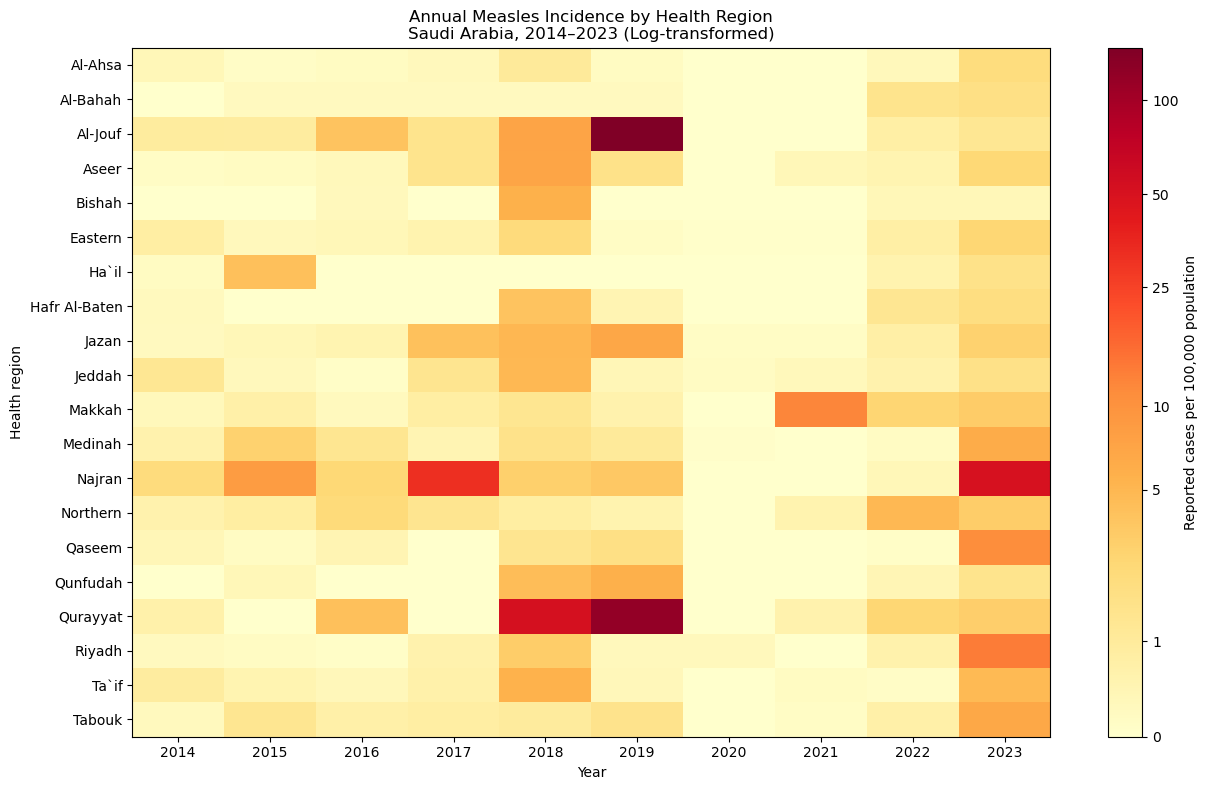

In [329]:
import numpy as np
import matplotlib.pyplot as plt

# applying log(1 + incidence)
log_incidence = np.log1p(incidence_matrix)

fig, ax = plt.subplots(figsize=(13, 8))

im = ax.imshow(
    log_incidence.values,
    aspect="auto",
    cmap="YlOrRd",
    interpolation="nearest"
)

ax.set_xticks(np.arange(len(incidence_matrix.columns)))
ax.set_xticklabels(incidence_matrix.columns)

ax.set_yticks(np.arange(len(incidence_matrix.index)))
ax.set_yticklabels(incidence_matrix.index)

ax.set_xlabel("Year")
ax.set_ylabel("Health region")

ax.set_title(
    "Annual Measles Incidence by Health Region\n"
    "Saudi Arabia, 2014–2023 (Log-transformed)"

)

# Colorbar labels in original incidence units
ticks = [0, 1, 5, 10, 25, 50, 100, 150]
ticks = [x for x in ticks if x <= incidence_matrix.max().max()]

cbar = fig.colorbar(
    im,
    ax=ax,
    ticks=np.log1p(ticks)
)

cbar.ax.set_yticklabels([str(x) for x in ticks])
cbar.set_label("Reported cases per 100,000 population")

plt.tight_layout()
plt.show()



In [330]:
national_rates = annual[["year", "reported_cases", "population"]].copy()

national_rates["national_rate"] = (
    national_rates["reported_cases"]
    / national_rates["population"]
)

oe_data = regional.merge(
    national_rates[["year", "national_rate"]],
    on = "year",
    how = "left",
    validate = "many_to_one"
)

oe_data["expected_cases"] = (
    oe_data["population"]
    * oe_data["national_rate"]
)


# Annual national populations
national_population = (
    annual[["year", "population"]]
    .rename(columns={"population": "national_population"})
)

# Add annual national population to each region-year observation
oe_data = oe_data.merge(
    national_population,
    on="year",
    how="left",
    validate="many_to_one"
)

# Calculate each region's population share within its year
oe_data["population_share"] = (
    oe_data["population"]
    / oe_data["national_population"]
)

# Verify that regional shares sum to 1 for each year
share_check = (
    oe_data.groupby("year")["population_share"].sum()
)

display(share_check)


year
2014    1.0
2015    1.0
2016    1.0
2017    1.0
2018    1.0
2019    1.0
2020    1.0
2021    1.0
2022    1.0
2023    1.0
Name: population_share, dtype: float64

In [331]:
#################################
# SIMULATED REGIONAL CASE COUNTS
#################################

In [332]:
############################
## SIMUALTION OF the 10 yeas
############################

import numpy as np
import pandas as pd

rng = np.random.default_rng(seed=42)

n_simulations = 20000

regions = sorted(oe_data["health_region"].unique())
years = sorted(oe_data["year"].unique())

simulated_totals = np.zeros(
    (n_simulations, len(regions)),
    dtype=int
)

for year in years:

    year_df = (
        oe_data[oe_data["year"] == year]
        .set_index("health_region")
        .loc[regions]
    )

    national_cases = int(
        annual.loc[
            annual["year"] == year,
            "reported_cases"
        ].iloc[0]
    )

probabilities = year_df["population_share"].to_numpy()

    # One simulated case allocation per simulation
simulated_counts = rng.multinomial(
        national_cases,
        probabilities,
        size=n_simulations
    )

    # Accumulate cases across the ten years
simulated_totals += simulated_counts

print("Simulation matrix shape:", simulated_totals.shape)

print(
    "All simulations preserve 5,997 cases:",
    np.all(simulated_totals.sum(axis=1) == 5997)
)
             

Simulation matrix shape: (20000, 20)
All simulations preserve 5,997 cases: False


In [333]:
print("Number of regions:", len(regions))
print("Number of years:", len(years))
print("Simulation totals shape:", simulated_totals.shape)
print("Simulated counts shape:", simulated_counts.shape)

Number of regions: 20
Number of years: 10
Simulation totals shape: (20000, 20)
Simulated counts shape: (20000, 20)


In [334]:

############################
## SIMULATION OF THE 10 YEARS
############################

import numpy as np
import pandas as pd

rng = np.random.default_rng(seed=42)

n_simulations = 20000

regions = sorted(oe_data["health_region"].unique())
years = sorted(oe_data["year"].unique())

simulated_totals = np.zeros(
    (n_simulations, len(regions)),
    dtype=int
)

# ONLY ONE LOOP
for year in years:

    year_df = (
        oe_data[oe_data["year"] == year]
        .set_index("health_region")
        .loc[regions]
    )

    national_cases = int(
        annual.loc[
            annual["year"] == year,
            "reported_cases"
        ].iloc[0]
    )

    # INSIDE THE LOOP
    probabilities = year_df["population_share"].to_numpy()

    # INSIDE THE SAME LOOP
    simulated_counts = rng.multinomial(
        national_cases,
        probabilities,
        size=n_simulations
    )

    # ACCUMULATE EACH YEAR
    simulated_totals += simulated_counts

    # DISPLAY PROGRESS AFTER EACH YEAR
    print(
        f"{year}: "
        f"added {national_cases} cases, "
        f"cumulative = {simulated_totals[0].sum()}"
    )

# OUTSIDE THE LOOP
print("\nFinal validation:")
print("Minimum:", simulated_totals.sum(axis=1).min())
print("Maximum:", simulated_totals.sum(axis=1).max())

print(
    "All simulations preserve national totals:",
    np.all(
        simulated_totals.sum(axis=1)
        == annual["reported_cases"].sum()
    )
)


2014: added 154 cases, cumulative = 154
2015: added 219 cases, cumulative = 373
2016: added 125 cases, cumulative = 498
2017: added 457 cases, cumulative = 955
2018: added 1156 cases, cumulative = 2111
2019: added 1024 cases, cumulative = 3135
2020: added 34 cases, cumulative = 3169
2021: added 327 cases, cumulative = 3496
2022: added 247 cases, cumulative = 3743
2023: added 2254 cases, cumulative = 5997

Final validation:
Minimum: 5997
Maximum: 5997
All simulations preserve national totals: True


In [335]:

# Aggregate observed and expected cases by region
oe_summary = (
    oe_data
    .groupby("health_region", as_index=False)
    .agg(
        observed_cases=("reported_cases", "sum"),
        expected_cases=("expected_cases", "sum"),
        population_exposure=("population", "sum")
    )
)

# Calculate actual observed-to-expected ratios
oe_summary["oe_ratio"] = (
    oe_summary["observed_cases"]
    / oe_summary["expected_cases"]
)

display(oe_summary.head())


,health_region,observed_cases,expected_cases,population_exposure,oe_ratio
0,Al-Ahsa,51,217.426292,12132673,0.234562
1,Al-Bahah,16,77.493691,4531270,0.206468
2,Al-Jouf,567,67.630506,3551052,8.383791
3,Aseer,253,328.866200,18168190,0.769310
4,Bishah,25,65.909975,3775568,0.379305


In [336]:


################################
# Calculating simulated O/E rates
################################


# Extract expected cases in the correct regional order
expected_by_region = (
    oe_summary
    .set_index("health_region")
    .loc[regions, "expected_cases"]
    .to_numpy()
)

# Calculate O/E ratios for all 1,000 simulations
simulated_oe = simulated_totals / expected_by_region

print("Simulated O/E matrix shape:", simulated_oe.shape)

# Calculate the central 95% null reference intervals
lower = np.quantile(simulated_oe, 0.025, axis=0)
upper = np.quantile(simulated_oe, 0.975, axis=0)

# Create a regional summary table
simulation_summary = pd.DataFrame({
    "health_region": regions,
    "null_lower_95": lower,
    "null_upper_95": upper
})

# Add the actual observed O/E ratios
simulation_summary = simulation_summary.merge(
    oe_summary[["health_region", "oe_ratio"]],
    on="health_region",
    validate="one_to_one"
)

display(simulation_summary)



Simulated O/E matrix shape: (20000, 20)


,health_region,null_lower_95,null_upper_95,oe_ratio
0,Al-Ahsa,0.869260,1.131418,0.234562
1,Al-Bahah,0.787161,1.225906,0.206468
2,Al-Jouf,0.768884,1.242043,8.383791
3,Aseer,0.897021,1.103792,0.769310
4,Bishah,0.773783,1.244121,0.379305
5,Eastern,0.926352,1.074055,0.407788
6,Ha`il,0.833925,1.172003,0.345591
7,Hafr Al-Baten,0.793866,1.220421,0.426555
8,Jazan,0.885703,1.116129,1.159334
9,Jeddah,0.935917,1.066250,0.606981


In [337]:
## Validating the simulated results


print("Number of regions:", len(simulation_summary))

print(
    "All lower bounds <= upper bounds:",
    (simulation_summary["null_lower_95"] <=
     simulation_summary["null_upper_95"]).all()
)

print(
    "All observed O/E ratios positive:",
    (simulation_summary["oe_ratio"] > 0).all()
)

print(
    "Mean simulated O/E close to 1:",
    np.round(simulated_oe.mean(axis=0), 2)
)



Number of regions: 20
All lower bounds <= upper bounds: True
All observed O/E ratios positive: True
Mean simulated O/E close to 1: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


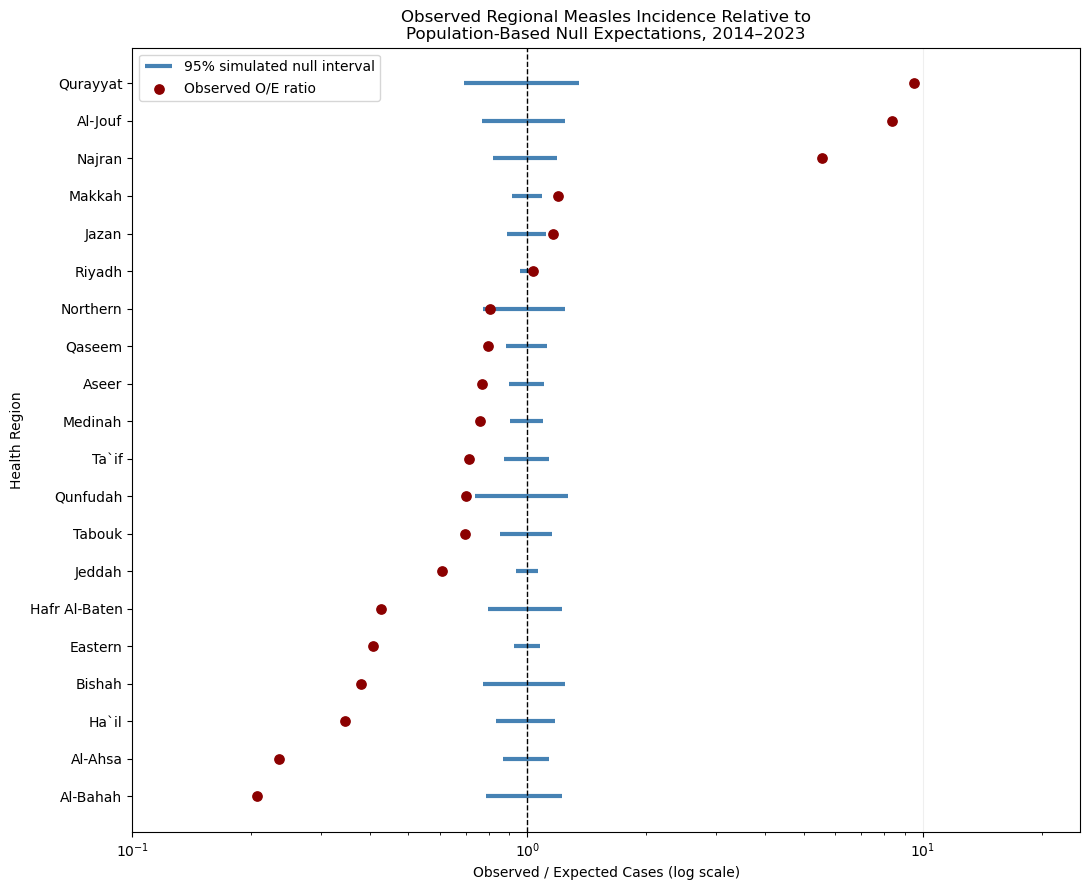

In [338]:
################################
# O/E ratios vs. simulated visualization
################################

import matplotlib.pyplot as plt
import numpy as np

# sort rigions by observed O/E ratio
plot_data = simulation_summary.sort_values("oe_ratio", ascending=True)

fig, ax = plt.subplots(figsize=(11, 9))
y = np.arange(len(plot_data))

# Plot simulated 95% null reference intervals
ax.hlines(
    y=y,
    xmin=plot_data["null_lower_95"],
    xmax=plot_data["null_upper_95"],
    color="steelblue",
    linewidth=3,
    label="95% simulated null interval"
)

# Plot observed O/E ratios
ax.scatter(
    plot_data["oe_ratio"],
    y,
    color="darkred",
    s=45,
    zorder=3,
    label="Observed O/E ratio"
)

# Reference line
ax.axvline(
    x=1,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_yticks(y)
ax.set_yticklabels(plot_data["health_region"])

ax.set_xlabel("Observed-to-Expected Ratio")
ax.set_ylabel("Health Region")

ax.set_title(
    "Observed Regional Measles Incidence Relative to\n"
    "Population-Based Null Expectations, 2014–2023"
)

ax.legend()
ax.grid(axis="x", alpha=0.2)
ax.set_xscale("log")
ax.set_xlabel("Observed / Expected Cases (log scale)")
ax.set_xlim(0.1, 25)


plt.tight_layout()
plt.show()


In [339]:
###################################################
# Simultaneous simulation-based reference intervals
###################################################

In [340]:
# to claculate annual national cases for each regional-year

annual_cases = annual [["year", "reported_cases"]].rename(
    columns = {"reported_cases": "annual_cases"}
)

variance_data = oe_data.merge(
    annual_cases,
    on = "year",
    how = "left",
    validate = "many_to_one"
)

variance_data["variance_componet"] = (
    variance_data["annual_cases"]
    * variance_data["population_share"]
    * (1 - variance_data["population_share"])
)

# sum variance contributions across the 10 years
regional_variance = (
    variance_data.groupby("health_region")
    ["variance_componet"]
    .sum()
    .reindex(regions)
)

regional_sd = np.sqrt(regional_variance.to_numpy())

print("Number of regional standard deviations:", len(regional_sd))
print("All standard deviations positive:", (regional_sd > 0).all())
print("First five SD values:", np.round(regional_sd[:5], 3))
    

Number of regional standard deviations: 20
All standard deviations positive: True
First five SD values: [14.475  8.745  8.177 17.63   8.073]


In [341]:
### now we used the 1000 simulated dataset and calculate
#   the maximum SD across all 20 regions

# expected cases alinged with the 20 regions
expected = (
    oe_summary.set_index("health_region")
    .loc[regions, "expected_cases"]
    .to_numpy()
)

# SD for every simulation and region
simulated_z = (
    simulated_totals - expected
) / regional_sd

max_deviation = np.max(
    np.abs(simulated_z),
    axis=1
)
    
# simulated 95% critical threshold
critical_value = np.quantile(
    max_deviation,
    0.95
)

print("Simulated critical value:", round(critical_value, 3))

      

Simulated critical value: 3.031


In [342]:
## Generate the complete regional results table

lower_counts = np.maximum(
    0,
    expected - critical_value * regional_sd
)

upper_counts = (
    expected + critical_value * regional_sd
)

# convert limits to O/E ratio units
simultaneous_table = pd.DataFrame({
    "health_region": regions,
    "observed_cases": (
        oe_summary.set_index("health_region")
        .loc[regions, "observed_cases"]
        .to_numpy()
    ),
    "expected_cases": expected,
    "oe_ratio": (
        oe_summary.set_index("health_region")
        .loc[regions, "oe_ratio"]
        .to_numpy()
    ),
    "null_sd": regional_sd,
    "simultaneous_lower_95": lower_counts / expected,
    "simultaneous_upper_95": upper_counts / expected
})

simultaneous_table = simultaneous_table.sort_values(
    "oe_ratio",
    ascending=False
).reset_index(drop=True)

display(simultaneous_table.round(3))



,health_region,observed_cases,expected_cases,oe_ratio,null_sd,simultaneous_lower_95,simultaneous_upper_95
0,Qurayyat,317,33.365,9.501,5.760,0.477,1.523
1,Al-Jouf,567,67.631,8.384,8.177,0.634,1.366
2,Najran,603,108.627,5.551,10.328,0.712,1.288
3,Makkah,545,456.722,1.193,20.536,0.864,1.136
4,Jazan,322,277.746,1.159,16.274,0.822,1.178
5,Riyadh,1600,1550.511,1.032,33.902,0.934,1.066
6,Northern,55,68.465,0.803,8.227,0.636,1.364
7,Qaseem,204,256.654,0.795,15.674,0.815,1.185
8,Aseer,253,328.866,0.769,17.630,0.838,1.162
9,Medinah,300,395.170,0.759,19.213,0.853,1.147


In [343]:

from pathlib import Path

# Create output folder if it doesn't exist
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Define file paths
csv_path = output_dir / "simultaneous_OE_results.csv"
xlsx_path = output_dir / "simultaneous_OE_results.xlsx"

# Export CSV with full numerical precision
simultaneous_table.to_csv(
    csv_path,
    index=False,
    float_format="%.6f"
)

# Export Excel
with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    simultaneous_table.to_excel(
        writer,
        sheet_name="Simultaneous_OE",
        index=False,
        float_format="%.6f"
    )

print("CSV saved:", csv_path.resolve())
print("Excel saved:", xlsx_path.resolve())


CSV saved: /Users/ahmedsallam/Documents/Measles_KSA/outputs/simultaneous_OE_results.csv
Excel saved: /Users/ahmedsallam/Documents/Measles_KSA/outputs/simultaneous_OE_results.xlsx


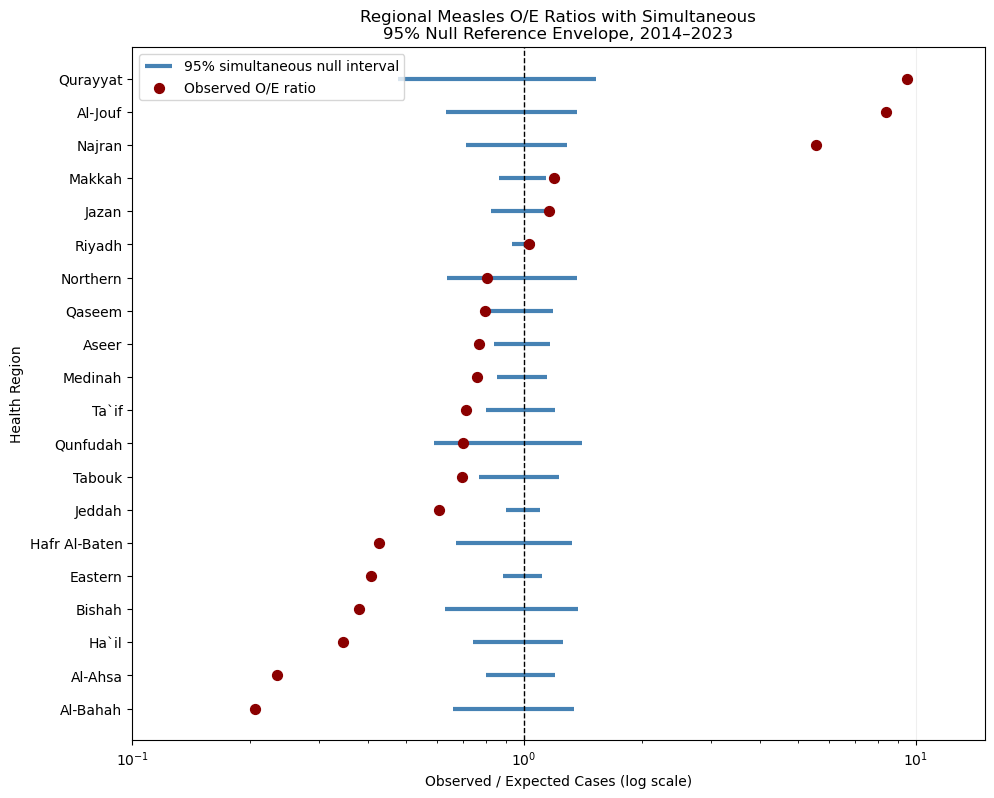

In [344]:
### Generate visualization

import matplotlib.pyplot as plt
import numpy as np


# sort regions by observed O/E ratio
plot_data = simultaneous_table.sort_values("oe_ratio", ascending=True).copy()

y = np.arange(len(plot_data))

fig, ax = plt.subplots(figsize=(11, 9))

ax.hlines(
    y=y,
    xmin=plot_data["simultaneous_lower_95"],
    xmax=plot_data["simultaneous_upper_95"],
    color="steelblue",
    linewidth=3,
    label="95% simultaneous null interval"

)

# plot observed O/E ratios
ax.scatter(
    plot_data["oe_ratio"],
    y,
    color="darkred",
    s=50,
    zorder=3,
    label = "Observed O/E ratio"
)

#reference line
ax.axvline(
    1,
    color="black",
    linestyle="--",
    linewidth=1
)
    
ax.set_xscale("log")
ax.set_xlim(0.1, 15)

ax.set_yticks(y)
ax.set_yticklabels(plot_data["health_region"])

ax.set_xlabel("Observed / Expected Cases (log scale)")
ax.set_ylabel("Health Region")

ax.set_title(
    "Regional Measles O/E Ratios with Simultaneous\n"
    "95% Null Reference Envelope, 2014–2023"
)

ax.legend(loc="upper left")
ax.grid(axis="x", alpha=0.2)

In [345]:

# Determine whether each simulated dataset falls
# within the simultaneous envelope for all 20 regions

lower_counts = (
    simultaneous_table.set_index("health_region")
    .loc[regions, "simultaneous_lower_95"]
    .to_numpy() * expected
)

upper_counts = (
    simultaneous_table.set_index("health_region")
    .loc[regions, "simultaneous_upper_95"]
    .to_numpy() * expected
)

inside_all = (
    (simulated_totals >= lower_counts) &
    (simulated_totals <= upper_counts)
).all(axis=1)

coverage = inside_all.mean()

print(f"Empirical simultaneous coverage: {coverage:.3f}")
print("Minimum lower O/E limit:",
      simultaneous_table["simultaneous_lower_95"].min())


Empirical simultaneous coverage: 0.950
Minimum lower O/E limit: 0.47670599335743474


In [346]:

# Independent validation of simultaneous coverage

rng_validation = np.random.default_rng(2026)
n_validation = 10000

validation_totals = np.zeros(
    (n_validation, len(regions)),
    dtype=int
)

for year in years:
    year_df = (
        oe_data[oe_data["year"] == year]
        .set_index("health_region")
        .loc[regions]
    )

    n_cases = int(
        annual.loc[
            annual["year"] == year,
            "reported_cases"
        ].iloc[0]
    )

    p = year_df["population_share"].to_numpy()

    validation_totals += rng_validation.multinomial(
        n=n_cases,
        pvals=p,
        size=n_validation
    )

# Validate case conservation
assert np.all(
    validation_totals.sum(axis=1)
    == annual["reported_cases"].sum()
)

# Calculate maximum standardized deviation
validation_z = (
    validation_totals - expected
) / regional_sd

validation_max = np.max(
    np.abs(validation_z),
    axis=1
)

# Apply the previously estimated critical value
independent_coverage = np.mean(
    validation_max <= critical_value
)

print(
    f"Independent simultaneous coverage: "
    f"{independent_coverage:.3f}"
)


Independent simultaneous coverage: 0.950


In [347]:

# Compare corrected theoretical SD with simulated SD
empirical_sd = simulated_totals.std(axis=0, ddof=1)

sd_ratio = regional_sd / empirical_sd

print("Minimum SD ratio:", round(sd_ratio.min(), 3))
print("Maximum SD ratio:", round(sd_ratio.max(), 3))

print(
    "SDs agree within 5%:",
    np.allclose(regional_sd, empirical_sd, rtol=0.05)
)


Minimum SD ratio: 0.989
Maximum SD ratio: 1.01
SDs agree within 5%: True


In [348]:
###################################################
# Population-weighted geographic concentration
###################################################

In [349]:
# aggrigate cases and population exposures by region

lorenz_data = (
    regional.groupby("health_region", as_index=False)
    .agg(
        total_cases=("reported_cases", "sum"),
        population_exposure=("population", "sum")
    )
)

# claculate regional incidence rate per 100,000 population-years
lorenz_data["incidence_per_100k"] = (
    lorenz_data["total_cases"]
    / lorenz_data["population_exposure"]
    * 100000
)

# Sort regions from low to high inceident
lorenz_data = lorenz_data.sort_values(
    "incidence_per_100k",
    ascending=True
).reset_index(drop=True)

# calculate population and case shares
lorenz_data["population_share"] = (
    lorenz_data["population_exposure"]
    / lorenz_data["population_exposure"].sum()
)

lorenz_data["case_share"] = (
    lorenz_data["total_cases"]
    / lorenz_data["total_cases"].sum()
)

display(lorenz_data.round(4))

,health_region,total_cases,population_exposure,incidence_per_100k,population_share,case_share
0,Al-Bahah,16,4531270,0.3531,0.0139,0.0027
1,Al-Ahsa,51,12132673,0.4204,0.0371,0.0085
2,Ha`il,46,7143656,0.6439,0.0218,0.0077
3,Bishah,25,3775568,0.6622,0.0115,0.0042
4,Eastern,254,33105189,0.7673,0.1013,0.0424
5,Hafr Al-Baten,36,4563071,0.7889,0.0140,0.0060
6,Jeddah,489,45118915,1.0838,0.1380,0.0815
7,Qunfudah,38,3056697,1.2432,0.0093,0.0063
8,Ta`if,160,12735124,1.2564,0.0390,0.0267
9,Tabouk,116,9147824,1.2681,0.0280,0.0193


In [350]:

from pathlib import Path

# Define output directory
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Define filenames
csv_path = output_dir / "lorenz_regional_data.csv"
xlsx_path = output_dir / "lorenz_regional_data.xlsx"

# Export CSV (preserve 6 decimal places)
lorenz_data.to_csv(
    csv_path,
    index=False,
    float_format="%.6f"
)

# Export Excel
with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    lorenz_data.to_excel(
        writer,
        sheet_name="Regional_Concentration",
        index=False
    )

    # Apply consistent numerical formatting
    ws = writer.sheets["Regional_Concentration"]

    for row in ws.iter_rows(min_row=2):
        for cell in row:
            if isinstance(cell.value, float):
                cell.number_format = "0.000000"

print("CSV saved:", csv_path.resolve())
print("Excel saved:", xlsx_path.resolve())
print("Exported rows:", len(lorenz_data))


CSV saved: /Users/ahmedsallam/Documents/Measles_KSA/outputs/lorenz_regional_data.csv
Excel saved: /Users/ahmedsallam/Documents/Measles_KSA/outputs/lorenz_regional_data.xlsx
Exported rows: 20


In [351]:
## validation


import numpy as np

print("Number of regions:", len(lorenz_data))
print("Total cases:", lorenz_data["total_cases"].sum())
print("Population shares sum:",
      lorenz_data["population_share"].sum())
print("Case shares sum:",
      lorenz_data["case_share"].sum())

print("Incidence correctly sorted:",
      lorenz_data["incidence_per_100k"].is_monotonic_increasing)


Number of regions: 20
Total cases: 5997
Population shares sum: 0.9999999999999999
Case shares sum: 0.9999999999999999
Incidence correctly sorted: True


In [352]:

# Calculate cumulative population and case shares
lorenz_data["cumulative_population"] = (
    lorenz_data["population_share"].cumsum()
)

lorenz_data["cumulative_cases"] = (
    lorenz_data["case_share"].cumsum()
)

# Include the origin (0, 0)
x = np.insert(
    lorenz_data["cumulative_population"].to_numpy(),
    0, 0
)

y = np.insert(
    lorenz_data["cumulative_cases"].to_numpy(),
    0, 0
)

# Calculate area under the Lorenz curve
area = np.trapz(y, x)

# Population-weighted Gini-type concentration index
gini = 1 - 2 * area

print(f"Area under Lorenz curve: {area:.4f}")
print(f"Population-weighted concentration index: {gini:.4f}")


Area under Lorenz curve: 0.3156
Population-weighted concentration index: 0.3687


In [353]:

print("Starts at origin:", x[0] == 0 and y[0] == 0)

print("Ends at (1,1):",
      np.allclose([x[-1], y[-1]], [1, 1]))

print("Cumulative shares increase:",
      np.all(np.diff(x) >= 0) and np.all(np.diff(y) >= 0))

print("Concentration index within [0,1]:",
      0 <= gini <= 1)


Starts at origin: True
Ends at (1,1): True
Cumulative shares increase: True
Concentration index within [0,1]: True


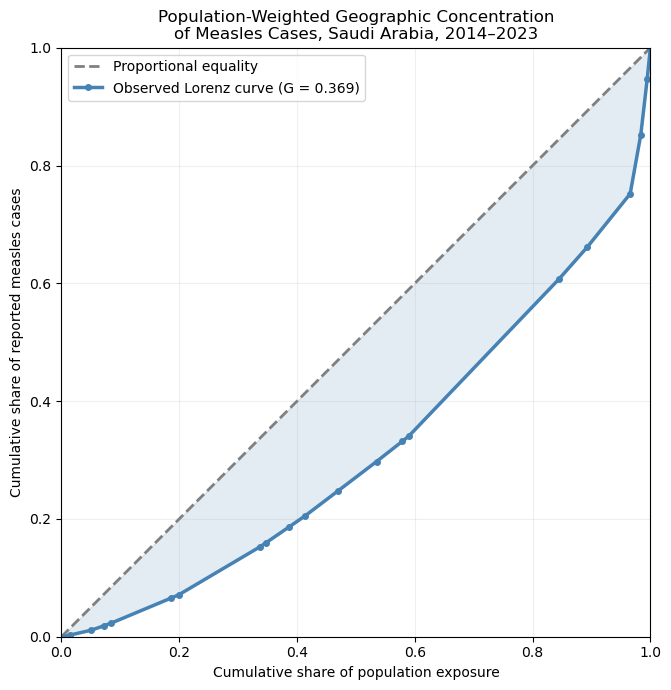

In [354]:

import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(8, 7))

# Line of proportional equality
ax.plot(
    [0, 1], [0, 1],
    color="gray",
    linestyle="--",
    linewidth=2,
    label="Proportional equality"
)

# Observed Lorenz curve
ax.plot(
    x, y,
    color="steelblue",
    linewidth=2.5,
    marker="o",
    markersize=4,
    label=f"Observed Lorenz curve (G = {gini:.3f})"
)

# Shade the difference between equality and observed distribution
ax.fill_between(
    x, y, x,
    color="steelblue",
    alpha=0.15
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel("Cumulative share of population exposure")
ax.set_ylabel("Cumulative share of reported measles cases")

ax.set_title(
    "Population-Weighted Geographic Concentration\n"
    "of Measles Cases, Saudi Arabia, 2014–2023"
)

ax.legend(loc="upper left")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


In [355]:
#########################
# Simulate the concentration index


# Regional population exposure, aligned with simulation columns
population_by_region = (
    regional.groupby("health_region")["population"]
    .sum()
    .reindex(regions)
    .to_numpy()
)

population_weights = (
    population_by_region / population_by_region.sum()
)

# Reusable function for grouped population-weighted Gini
def calculate_gini(cases, population):
    rates = cases / population
    order = np.argsort(rates)

    sorted_cases = cases[order]
    sorted_population = population[order]

    cumulative_pop = np.concatenate((
        [0], np.cumsum(sorted_population) / population.sum()
    ))

    cumulative_cases = np.concatenate((
        [0], np.cumsum(sorted_cases) / cases.sum()
    ))

    return 1 - 2 * np.trapz(
        cumulative_cases, cumulative_pop
    )

# Calculate concentration for each simulated dataset
# Calculate concentration for each simulated dataset
simulated_gini = np.array([
    calculate_gini(simulated_totals[i], population_by_region)
    for i in range(simulated_totals.shape[0])
])

print("Simulated Gini values:", len(simulated_gini))
print("Mean simulated Gini:", round(simulated_gini.mean(), 4))
print(
    "95% null reference interval:",
    np.round(np.quantile(simulated_gini, [0.025, 0.975]), 4)
)


Simulated Gini values: 20000
Mean simulated Gini: 0.0309
95% null reference interval: [0.0209 0.0419]


In [356]:

observed_cases = (
    regional.groupby("health_region")["reported_cases"]
    .sum()
    .reindex(regions)
    .to_numpy()
)

gini_check = calculate_gini(
    observed_cases, population_by_region
)

print("Original observed Gini:", round(gini, 6))
print("Function-based Gini:", round(gini_check, 6))

print(
    "Calculations match:",
    np.isclose(gini, gini_check, atol=1e-10)
)

print(
    "Simulated Gini values within [0,1]:",
    np.all((simulated_gini >= 0) & (simulated_gini <= 1))
)


Original observed Gini: 0.368706
Function-based Gini: 0.368706
Calculations match: True
Simulated Gini values within [0,1]: True


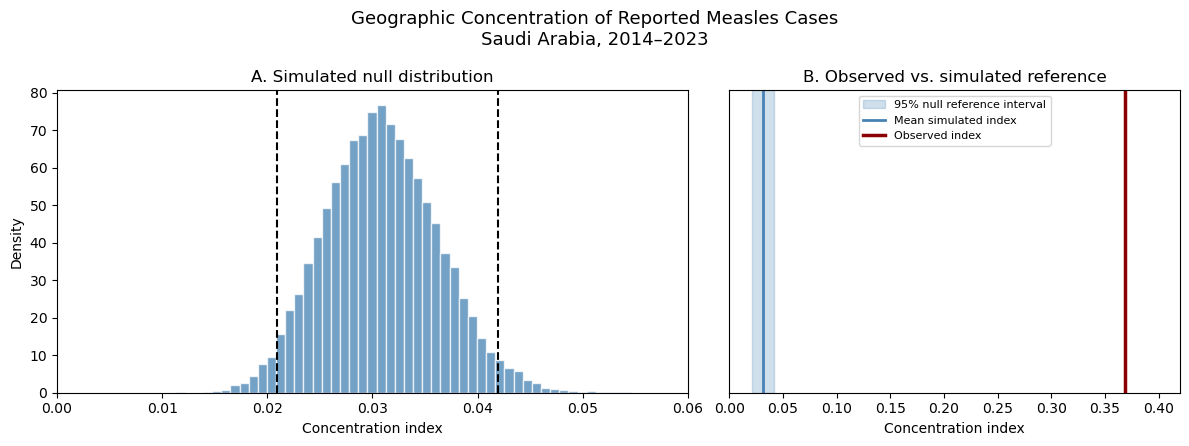

In [357]:
## Visualize the concentration-index distribution


fig, axes = plt.subplots(
    1, 2, figsize=(12, 4.5),
    gridspec_kw={"width_ratios": [1.4, 1]}
)

# Panel A: Zoomed simulated distribution
axes[0].hist(
    simulated_gini,
    bins=50,
    density=True,
    color="steelblue",
    alpha=0.75,
    edgecolor="white"
)

axes[0].axvline(null_lower, color="black", linestyle="--")
axes[0].axvline(null_upper, color="black", linestyle="--")

axes[0].set_title("A. Simulated null distribution")
axes[0].set_xlabel("Concentration index")
axes[0].set_ylabel("Density")
axes[0].set_xlim(0, 0.06)

# Panel B: Observed versus simulated reference
axes[1].axvspan(
    null_lower, null_upper,
    color="steelblue",
    alpha=0.25,
    label="95% null reference interval"
)

axes[1].axvline(
    simulated_gini.mean(),
    color="steelblue",
    linewidth=2,
    label="Mean simulated index"
)

axes[1].axvline(
    gini,
    color="darkred",
    linewidth=2.5,
    label="Observed index"
)

axes[1].set_title("B. Observed vs. simulated reference")
axes[1].set_xlabel("Concentration index")
axes[1].set_xlim(0, 0.42)
axes[1].set_yticks([])
axes[1].legend(fontsize=8, loc="upper center")

fig.suptitle(
    "Geographic Concentration of Reported Measles Cases\n"
    "Saudi Arabia, 2014–2023",
    fontsize=13
)

plt.tight_layout()
plt.show()


In [358]:
# Calculate a simulation-based tail probability

# Monte Carlo upper-tail probability
n_extreme = np.sum(simulated_gini >= gini)

p_mc = (n_extreme + 1) / (len(simulated_gini) + 1)

print("Simulations at least as concentrated:", n_extreme)
print(f"Monte Carlo upper-tail p-value: {p_mc:.6f}")


Simulations at least as concentrated: 0
Monte Carlo upper-tail p-value: 0.000050


In [359]:
##############################################
####   Regional peak-year concentration ######
##############################################

In [360]:
###########################
## Calculate the regional summaries

# total reported cases across 2014-2023
regional_totals = (
    regional.groupby("health_region")["reported_cases"]
    .sum()
    .rename("total_cases")
)

# Identify the year with the most cases for each region
peak_years = (
    regional.sort_values(
        ["health_region", "reported_cases", "year"],
        ascending=[True, False, True]
    )
    .drop_duplicates("health_region")
    [["health_region","year", "reported_cases"]]
    .rename(columns={
        "year": "peak_year",
        "reported_cases": "peak_year_cases"
    })
)

# combine peak year with 10 year totals
peak_summary = peak_years.merge(
    regional_totals,
    on="health_region",
    validate="one_to_one"
)

# percentage of regional cases in the peak year
peak_summary["peak_year_share_pct"]=(
    peak_summary["peak_year_cases"]
    / peak_summary["total_cases"]
    * 100
)

peak_summary = peak_summary.sort_values(
    "peak_year_share_pct",
    ascending=False

).reset_index(drop=True)

display(peak_summary.round(2))



,health_region,peak_year,peak_year_cases,total_cases,peak_year_share_pct
0,Al-Jouf,2019,510,567,89.95
1,Bishah,2018,22,25,88.00
2,Riyadh,2023,1157,1600,72.31
3,Qaseem,2023,144,204,70.59
4,Qurayyat,2019,207,317,65.30
5,Ha`il,2015,29,46,63.04
6,Makkah,2021,297,545,54.50
7,Aseer,2018,130,253,51.38
8,Tabouk,2023,59,116,50.86
9,Najran,2023,305,603,50.58


In [361]:

from pathlib import Path
import pandas as pd

# Define output directory
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Define file paths
csv_path = output_dir / "regional_peak_year_concentration.csv"
xlsx_path = output_dir / "regional_peak_year_concentration.xlsx"

# Export CSV with 6 decimal places
peak_summary.to_csv(
    csv_path,
    index=False,
    float_format="%.6f"
)

# Export Excel
with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    peak_summary.to_excel(
        writer,
        sheet_name="Peak_Year_Concentration",
        index=False
    )

    ws = writer.sheets["Peak_Year_Concentration"]

    # Format percentage values to 2 decimal places
    pct_col = peak_summary.columns.get_loc("peak_year_share_pct") + 1

    for row in range(2, len(peak_summary) + 2):
        ws.cell(row=row, column=pct_col).number_format = '0.00"%"'

    # Adjust column widths
    for column in ws.columns:
        col_letter = column[0].column_letter
        max_length = max(
            len(str(cell.value)) if cell.value is not None else 0
            for cell in column
        )
        ws.column_dimensions[col_letter].width = min(max_length + 3, 35)

print("CSV saved:", csv_path.resolve())
print("Excel saved:", xlsx_path.resolve())
print("Exported regions:", len(peak_summary))


CSV saved: /Users/ahmedsallam/Documents/Measles_KSA/outputs/regional_peak_year_concentration.csv
Excel saved: /Users/ahmedsallam/Documents/Measles_KSA/outputs/regional_peak_year_concentration.xlsx
Exported regions: 20


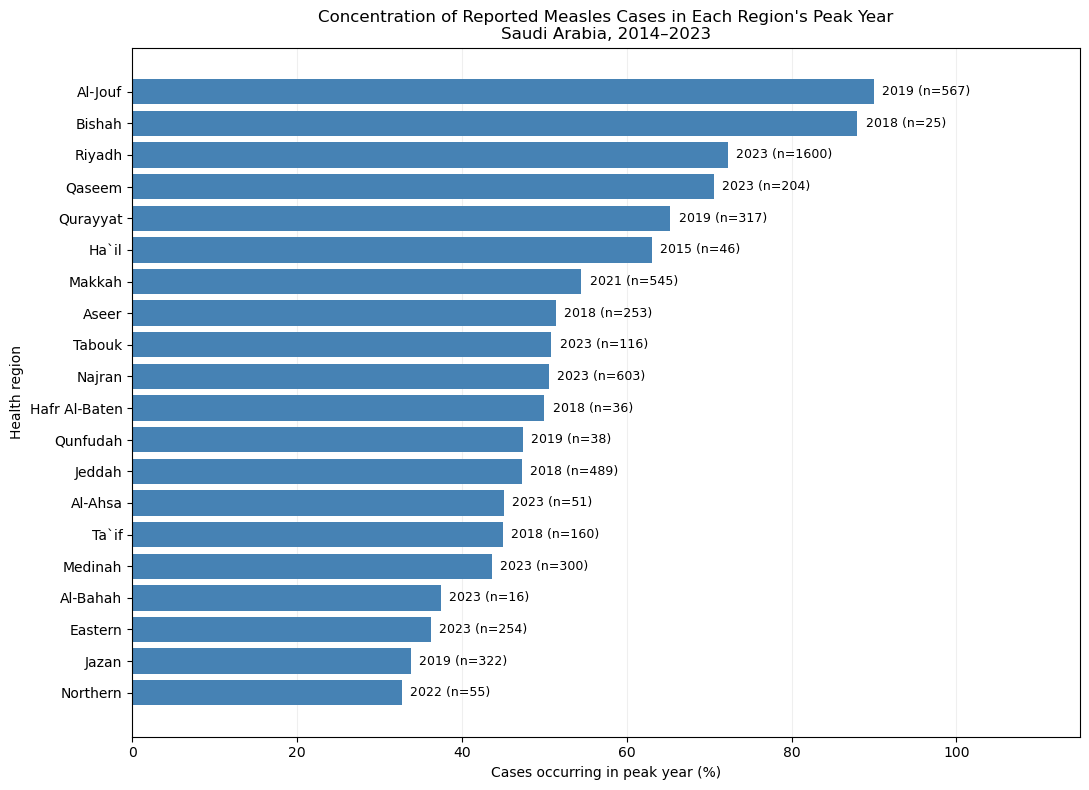

In [362]:
### visulaise

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize = (11, 8))

ax.barh(
    peak_summary["health_region"],
    peak_summary["peak_year_share_pct"],
    color = "steelblue"
)

# show peak year and regional total beside each bar
for i, row in peak_summary.iterrows():
    ax.text(
        row["peak_year_share_pct"] + 1,
        i,
        f'{int(row["peak_year"])} (n={int(row["total_cases"])})',
        va="center",
        fontsize=9
    )

ax.invert_yaxis()

ax.set_xlim(0, 115)
ax.set_xlabel("Cases occurring in peak year (%)")
ax.set_ylabel("Health region")

ax.set_title(
    "Concentration of Reported Measles Cases "
    "in Each Region's Peak Year\n"
    "Saudi Arabia, 2014–2023"
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [363]:
##################################################
##### Regional Annual Incidence Trajectories #####
##################################################

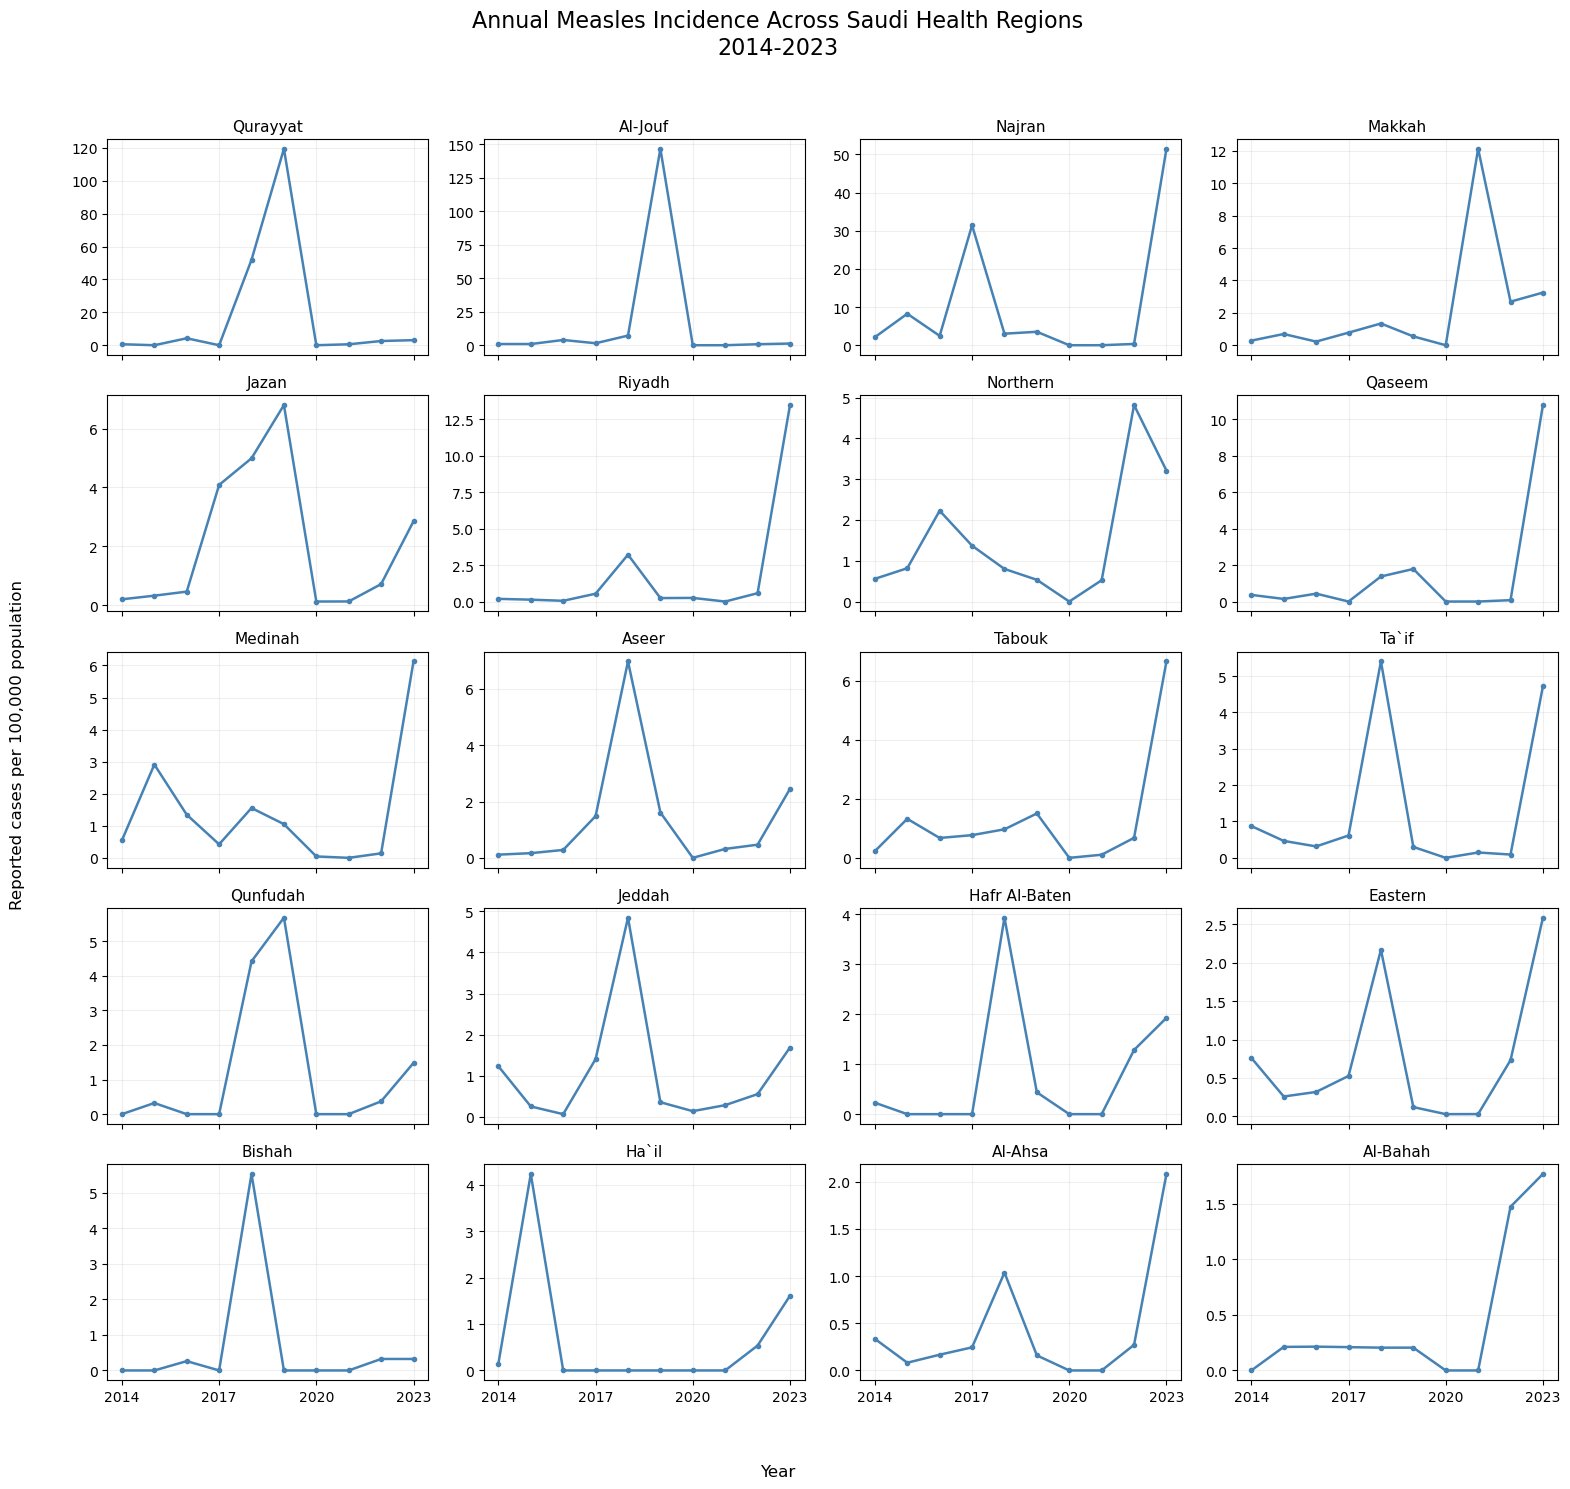

In [364]:
import matplotlib.pyplot as plt
import numpy as np

# order regions by ten-year average annual incience
region_order = (
    regional.groupby("health_region")[
    "region_aair_per_100k_per_year"
    ]
    .first()
    .sort_values(ascending=False)
    .index
)

# create a 5-row x 4-column grid
fig, axes = plt.subplots(
    nrows=5,
    ncols=4,
    figsize=(16, 15),
    sharex=True,
    sharey=False,
)

axes = axes.flatten()

years = np.arange(2014, 2023)

for ax, region in zip(axes, region_order):

    region_data = (
        regional[regional["health_region"] == region]
        .sort_values("year")
    )

    ax.plot(
        region_data["year"],
        region_data["annual_incidence_per_100k"],
        color="steelblue",
        linewidth=1.8,
        marker="o",
        markersize=3
    )

    ax.set_title(region, fontsize=11)
    ax.set_xticks([2014, 2017, 2020, 2023])
    ax.grid(alpha=0.2)

    fig.suptitle(
        "Annual Measles Incidence Across Saudi Health Regions\n"
        "2014-2023",
        fontsize=16,
        y=0.99
    )

    fig.supxlabel("Year", fontsize=12)
    fig.supylabel(
    "Reported cases per 100,000 population",
    fontsize=12
)

plt.tight_layout(rect=[0.03, 0.03, 1, 0.97])
plt.show()

In [365]:
print ("Regions plotted:", len(region_order))
print ("Number of panel", len (axes))

print(
    "All regions have10 years:",
    regional.groupby("health_region")["year"]
    .nunique().eq(10).all()
)

print(
    "All incident values non-negative:",
    (regional["annual_incidence_per_100k"] >= 0).all()
)

Regions plotted: 20
Number of panel 20
All regions have10 years: True
All incident values non-negative: True
